# Sujet 5 — Surveiller le compresseur d'un métro (pannes réelles)
**AML313 · Séries temporelles de capteurs IoT · Master SupNum — Groupe 5**
Abderahmane Abderrahmane (22053) · Hafssatou Bilal (22067)

**Question métier :** alerter *avant* une défaillance du compresseur (APU), dans une fenêtre utile pour l'atelier.
**Données :** UCI MetroPT-3 (Porto, févr.–sept. 2020). **Baseline exigée :** résidu de prévision + seuil + persistance.
**Métriques :** rappel par événement, avance d'alerte (courbe P-F), fausses alertes par mois.

> Ce notebook est ré-exécuté automatiquement par `bash run_all.sh` (commande unique).
> Le calcul lourd et toutes les décisions de protocole sont dans `src/` (code testable, journalisé dans `results/pipeline.log`) ;
> le notebook les appelle et commente les résultats.

**Règles anti-fuite appliquées** (critère éliminatoire du sujet)
1. Chaque indicateur d'un cycle n'utilise que des mesures **≤ fin du cycle** ; l'instant de décision est la fin du cycle.
2. Aucune fenêtre centrée, aucun `bfill`, aucune interpolation à travers une coupure.
3. Découpage **chronologique** train → *gap 3 j* → validation → *gap 3 j* → test.
4. Scaler, Ridge, Isolation Forest, ACP et seuils ajustés sur le **train seul** ; (quantile, persistance) choisis sur la **validation** ; **test utilisé une seule fois**.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
sys.path.insert(0, "src")
from features import load_raw, diagnose_grid, build_cycles, ROLL_N
from evaluation import FAILURES
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = Path("results"); FIG = RES / "figures"
df = load_raw("data/MetroPT3(AirCompressor).csv")
print(f"{len(df):,} lignes, du {df.timestamp.min()} au {df.timestamp.max()}")
df.head()

1,516,948 lignes, du 2020-02-01 00:00:00 au 2020-09-01 03:59:50


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


---
## Phase 1 · Diagnostic du jeu brut (question 1)
Grille temporelle, doublons, manquants, ordres de grandeur et régimes marche/arrêt.

In [2]:
diag = diagnose_grid(df)
pd.Series(diag)

n_rows                                                        1516948
start                                             2020-02-01 00:00:00
end                                               2020-09-01 03:59:50
dt_median_s                                                      10.0
dt_share_9_13s                                               0.999756
n_duplicated_ts                                                     0
n_missing_values                                                    0
n_gaps_gt_60s                                                     331
gap_hours_total                                              909.5175
n_gaps_gt_1h                                                      160
max_gap_hours                                               48.032778
regime_share        {'arret': 0.5464, 'vide': 0.2951, 'charge': 0....
dtype: object

Pas d'échantillonnage (s) :
timestamp
10.0    1337521
9.0      128277
12.0      38321
13.0       7988
11.0       4471
21.0         10
Name: count, dtype: int64


,min,50%,max
timestamp,2020-02-01 00:00:00,2020-05-17 08:07:06,2020-09-01 03:59:50
TP2,-0.032,-0.012,10.676
TP3,0.73,8.96,10.302
H1,-0.036,8.784,10.288
DV_pressure,-0.032,-0.02,9.844
Reservoirs,0.712,8.96,10.3
Oil_temperature,15.4,62.7,89.05
Motor_current,0.02,0.045,9.295
COMP,0.0,1.0,1.0
DV_eletric,0.0,0.0,1.0


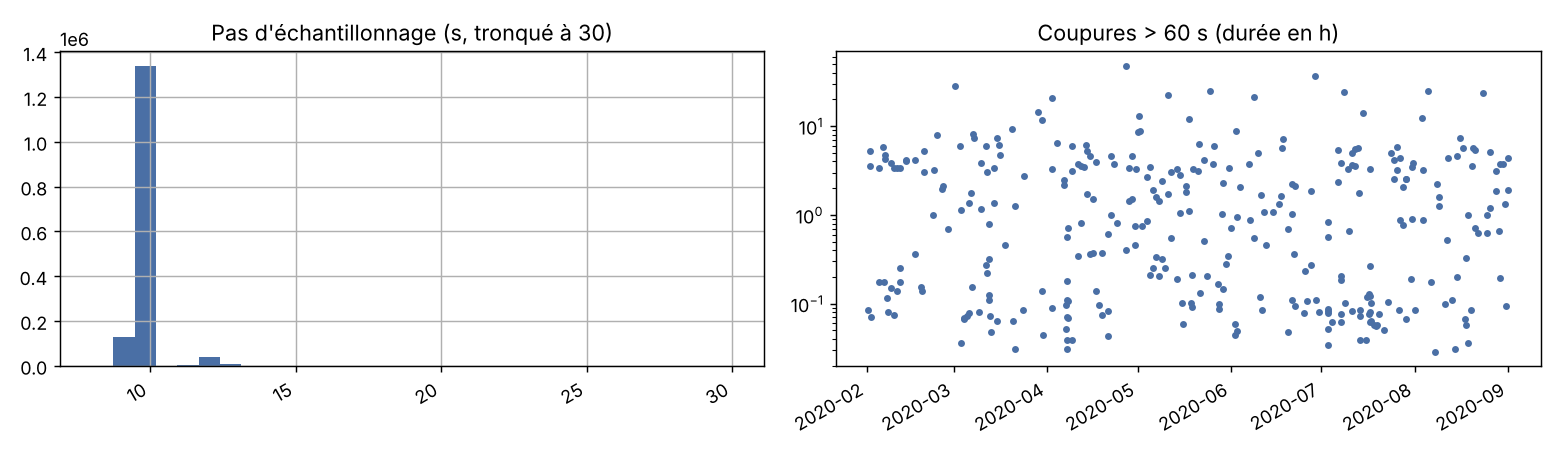

In [3]:
dt = df["timestamp"].diff().dt.total_seconds()
print("Pas d'échantillonnage (s) :"); print(dt.value_counts().head(6))
display(df.describe().T[["min", "50%", "max"]].round(3))
display(Image(FIG / "01_grille.png"))

**Lecture du diagnostic**
* Le fichier public n'est pas à 1 Hz : il est **décimé à ~10 s** (pas médian 10 s, 99,98 % des pas entre 9 et 13 s). 1 516 948 lignes, **0 doublon, 0 valeur manquante** codée.
* **331 coupures > 60 s** (≈ 910 h), dont 160 > 1 h (max 48 h) : rame hors tension (nuit, dépôt, immobilisations). Mécanisme : manquant *non aléatoire* lié à l'exploitation (le train est éteint) → **aucune imputation** ; une coupure ferme une « session » et rien n'est calculé à travers elle.
* Régimes (courant moteur et signal `COMP`) : arrêt ≈ 55 %, marche à vide ≈ 30 %, **charge ≈ 16 %**.
* Attention : pendant les pannes #1 et #3 les capteurs sont figés ou absents (rame immobilisée) : la détection doit se faire **avant**.

### Hypothèse et baseline écrites AVANT tout modèle
* **Hypothèse physique :** une fuite d'air fait chuter plus vite la pression des réservoirs au repos ; le compresseur redémarre plus souvent et charge plus longtemps (rapport de service ↑, température d'huile ↑).
* **Agrégat :** une moyenne horaire écraserait des phases de charge de ~2 min ; on rééchantillonne **par cycle de compression** (une ligne par cycle de charge).
* **Baseline (imposée) :** prévoir le taux de chute de pression au repos à partir du seul contexte d'exploitation (heure, week-end) par une Ridge apprise sur la période normale ; **résidu** standardisé lissé par EWMA causale ; **seuil** = quantile du résidu d'entraînement ; **persistance** K cycles.

---
## Phase 2 · Préparation causale et indicateurs par cycle (question 2)
Code : `src/features.py`. Les grandeurs inter-cycles (`idle_before_s`, `leak_rate`, `duty_cycle`) sont calculées avec le **cycle précédent** (connu au début du cycle courant), et les tendances sont des **médianes glissantes sur les 15 cycles passés**.
> Correction par rapport à la première version : `idle_sec` utilisait le début du cycle *suivant* puis `bfill()` → information future. Supprimé.

In [4]:
cyc = build_cycles(df)
cols = ["start_time", "end_time", "duration_s", "pressure_gain", "gain_rate", "idle_before_s",
        "leak_rate", "duty_cycle", "oil_temp_max", "current_mean", f"leak_rate_med{ROLL_N}"]
print(f"{len(cyc):,} cycles ; grandeurs inter-cycles non définies en début de session : {cyc.idle_before_s.isna().sum()} (laissées NaN)")
cyc[cols].head()

10,751 cycles ; grandeurs inter-cycles non définies en début de session : 297 (laissées NaN)


,start_time,end_time,duration_s,pressure_gain,gain_rate,idle_before_s,leak_rate,duty_cycle,oil_temp_max,current_mean,leak_rate_med15
0,2020-02-01 00:23:08,2020-02-01 00:24:47,99.0,1.958,1.186667,NaN,NaN,NaN,50.025,5.943409,NaN
1,2020-02-01 00:57:19,2020-02-01 00:58:48,89.0,1.998,1.346966,1952.0,0.060430,0.043606,49.850,6.042500,NaN
2,2020-02-01 01:30:41,2020-02-01 01:32:10,89.0,1.928,1.299775,1913.0,0.062603,0.044456,49.625,6.033500,NaN
3,2020-02-01 02:04:23,2020-02-01 02:05:52,89.0,1.906,1.284944,1933.0,0.059845,0.044016,49.725,6.040000,NaN
4,2020-02-01 02:37:54,2020-02-01 02:39:24,90.0,1.956,1.304000,1922.0,0.059438,0.044732,49.600,6.008000,NaN


In [5]:
# Vérification automatique de causalité : recalculer les indicateurs en tronquant les données
# à une date t ne doit pas changer les cycles terminés avant t.
t = pd.Timestamp("2020-05-20 12:00")
cyc_trunc = build_cycles(df[df.timestamp <= t])
a = cyc[cyc.end_time < t - pd.Timedelta(minutes=5)].reset_index(drop=True)
b = cyc_trunc[cyc_trunc.end_time < t - pd.Timedelta(minutes=5)].reset_index(drop=True)
num = a.select_dtypes("number").columns
same = np.allclose(a[num].fillna(-999).values, b[num].fillna(-999).values)
print("Indicateurs identiques avec ou sans le futur :", same)
assert same

Indicateurs identiques avec ou sans le futur : True


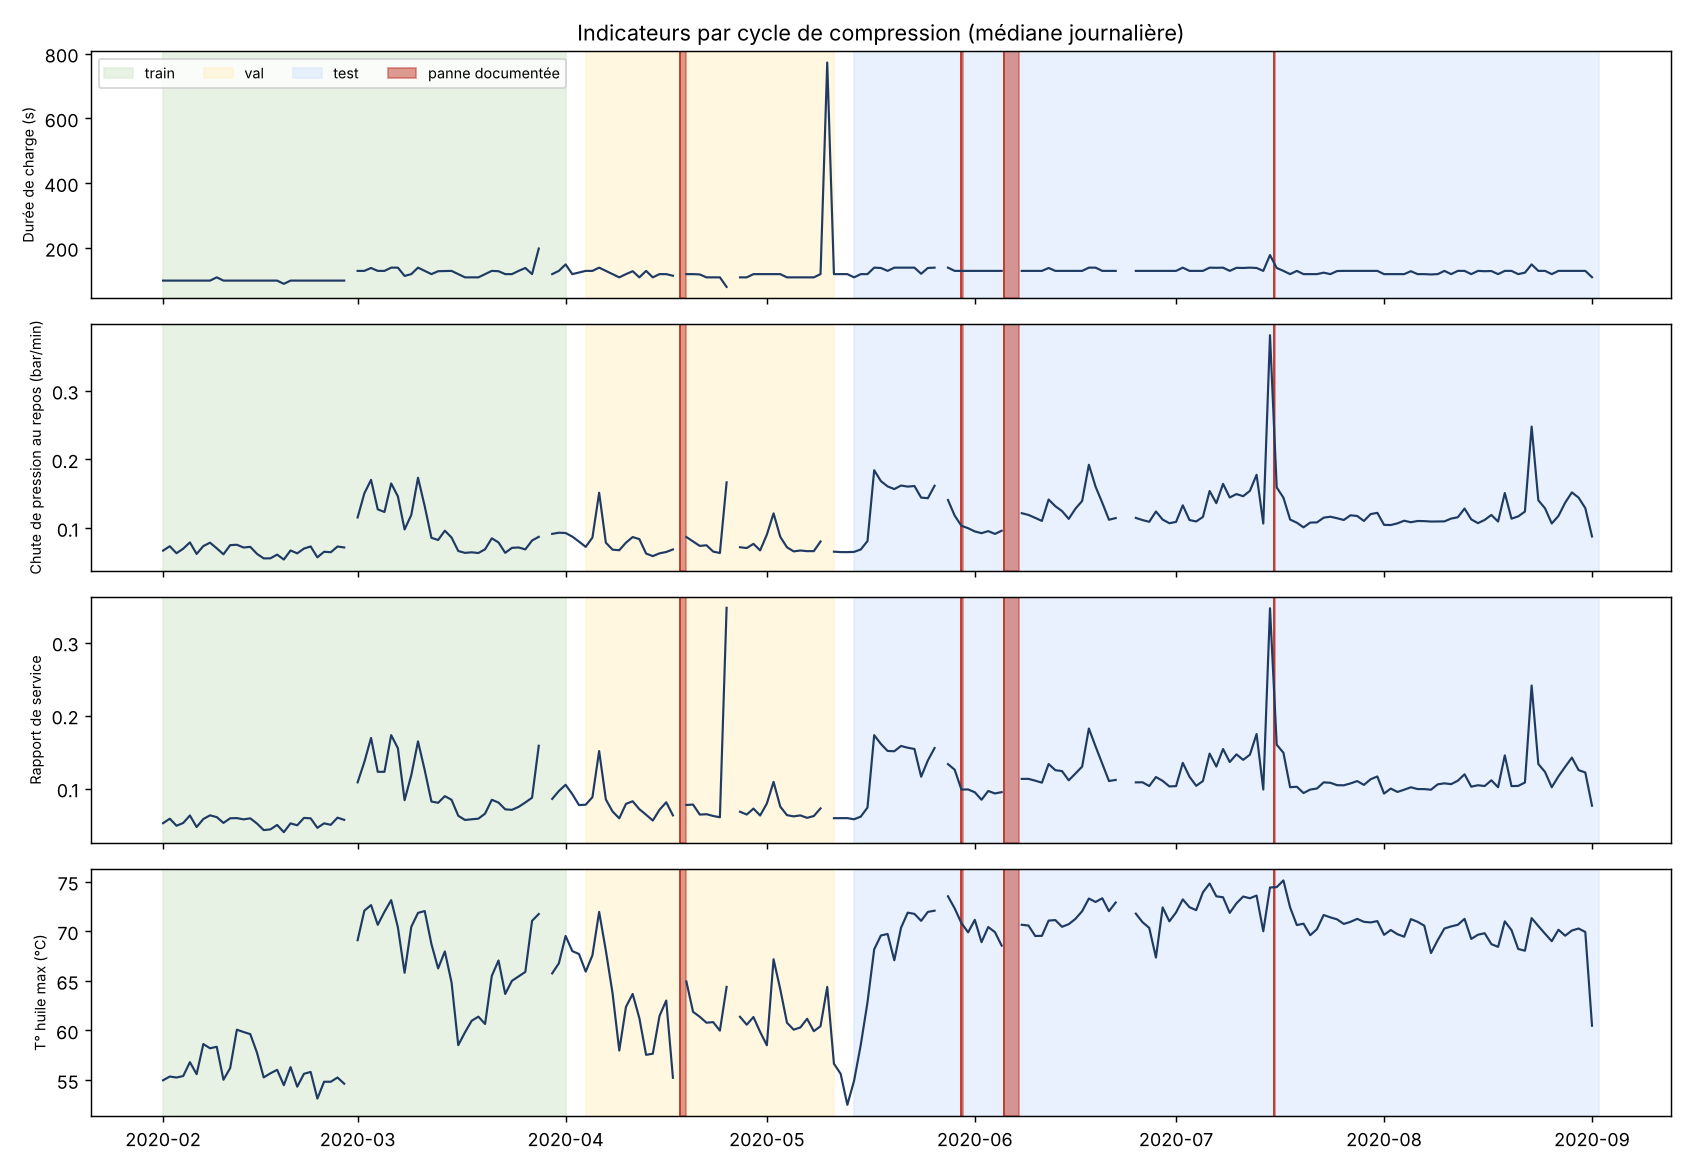

In [6]:
display(Image(FIG / "02_indicateurs_cycles.png"))

### Période normale et découpage chronologique
| Bloc | Dates | Rôle |
|---|---|---|
| Train | 01/02 → 31/03/2020 | apprentissage du « normal » (aucune panne signalée) |
| *gap* | 01/04 → 03/04 | 3 jours > mémoire des indicateurs (15 cycles ≈ 8 h, EWMA, persistance) |
| Validation | 04/04 → 10/05 | choix du quantile et de la persistance (contient la panne #1) |
| *gap* | 11/05 → 13/05 | |
| Test | 14/05 → 01/09 | **une seule évaluation** (pannes #2, #3, #4) |

Nettoyage de la référence, **calculé sur le train seul** : les journées dont la chute de pression médiane dépasse médiane + 3 MAD des journées d'entraînement sont retirées de la référence (01–11 mars : hausse de consommation non expliquée par le rapport).

In [7]:
R = json.load(open(RES / "resultats.json"))
print("Jours exclus de la référence :", R["jours_exclus_reference"])
print("Configuration retenue sur VALIDATION :")
pd.DataFrame(R["configuration_choisie_sur_validation"]).T

Jours exclus de la référence : ['2020-03-01', '2020-03-02', '2020-03-03', '2020-03-04', '2020-03-05', '2020-03-06', '2020-03-07', '2020-03-09', '2020-03-10', '2020-03-11']
Configuration retenue sur VALIDATION :


,quantile,persistance,seuil
Baseline (résidu Ridge + EWMA),0.99,1.0,1.182725
Isolation Forest,0.95,6.0,0.527301
ACP (T² / SPE),0.95,6.0,9.724296


---
## Phase 3 · Détecteurs (question 3) et choix sur validation
* **Baseline** : Ridge (contexte → taux de chute de pression), résidu standardisé, EWMA (span 10), seuil, persistance. La température d'huile n'est **pas** utilisée comme contexte : elle est elle-même augmentée par une fuite.
* **Isolation Forest** (200 arbres, graine 42) sur 12 indicateurs par cycle.
* **ACP** (90 % de variance) : max(T² de Hotelling, SPE) normalisés.

Règle de choix (sur validation) : FA/mois ≤ 2, puis rappel par événement maximal, puis réglage le **plus sensible** (asymétrie des coûts).

In [8]:
g = pd.read_csv(RES / "grille_validation.csv")
g.pivot_table(index=["detecteur", "quantile"], columns="persistance", values="FA_mois_val").round(2)

persistance                                  1     3     6
detecteur                      quantile                   
ACP (T² / SPE)                 0.950      7.89  4.51  1.13
                               0.980     13.53  2.25  0.00
                               0.990     11.27  0.00  0.00
                               0.995      7.89  0.00  0.00
                               0.999      3.38  0.00  0.00
Baseline (résidu Ridge + EWMA) 0.950      5.64  3.38  3.38
                               0.980      2.25  2.25  2.25
                               0.990      0.00  0.00  0.00
                               0.995      0.00  0.00  0.00
                               0.999      0.00  0.00  0.00
Isolation Forest               0.950     10.15  3.38  1.13
                               0.980     10.15  1.13  1.13
                               0.990      4.51  0.00  0.00
                               0.995      3.38  0.00  0.00
                               0.999      0.00  0.00  0.00

---
## Évaluation unique sur le TEST (question 4) — frise et avance d'alerte P-F
Une alarme est **utile** si elle survient dans `[début panne − 7 j, début panne[`. Une alarme pendant la panne est **tardive** et ne compte pas.
Les alarmes espacées de moins de 24 h forment un seul **épisode** ; un épisode hors fenêtre de panne (de −7 j à maintenance + 24 h) est une **fausse alerte**.

In [9]:
m = pd.read_csv(RES / "metriques_par_split.csv")
m[["detecteur", "split", "n_pannes", "n_detectees_avant", "rappel_IC95", "fausses_alertes",
   "mois_sains_surveilles", "FA_par_mois", "FA_par_mois_IC95", "part_cycles_en_alarme", "rappel_detecteur_aleatoire"]]

,detecteur,split,n_pannes,n_detectees_avant,rappel_IC95,fausses_alertes,mois_sains_surveilles,FA_par_mois,FA_par_mois_IC95,part_cycles_en_alarme,rappel_detecteur_aleatoire
0,Baseline (résidu Ridge + EWMA),val,1,0,"[0.0, 0.975]",0,0.89,0.00,"[0.0, 4.16]",0.0029,0.000
1,Baseline (résidu Ridge + EWMA),test,3,3,"[0.292, 1.0]",14,2.60,5.39,"[2.95, 9.05]",0.1573,0.711
2,Isolation Forest,val,1,0,"[0.0, 0.975]",1,0.89,1.13,"[0.03, 6.28]",0.0366,0.228
3,Isolation Forest,test,3,3,"[0.292, 1.0]",19,2.60,7.32,"[4.41, 11.43]",0.3450,0.814
4,ACP (T² / SPE),val,1,0,"[0.0, 0.975]",1,0.89,1.13,"[0.03, 6.28]",0.0359,0.228
5,ACP (T² / SPE),test,3,3,"[0.292, 1.0]",15,2.60,5.78,"[3.23, 9.53]",0.2196,0.735


In [10]:
pd.read_csv(RES / "detection_par_panne.csv")

,detecteur,split,panne,debut,detectee_avant,avance_h,alarme_tardive_seulement
0,Baseline (résidu Ridge + EWMA),val,#1,2020-04-18 00:00:00,False,NaN,False
1,Baseline (résidu Ridge + EWMA),test,#2,2020-05-29 23:30:00,True,167.3,False
2,Baseline (résidu Ridge + EWMA),test,#3,2020-06-05 10:00:00,True,94.2,False
3,Baseline (résidu Ridge + EWMA),test,#4,2020-07-15 14:30:00,True,167.0,False
4,Isolation Forest,val,#1,2020-04-18 00:00:00,False,NaN,False
5,Isolation Forest,test,#2,2020-05-29 23:30:00,True,167.3,False
6,Isolation Forest,test,#3,2020-06-05 10:00:00,True,167.7,False
7,Isolation Forest,test,#4,2020-07-15 14:30:00,True,167.0,False
8,ACP (T² / SPE),val,#1,2020-04-18 00:00:00,False,NaN,False
9,ACP (T² / SPE),test,#2,2020-05-29 23:30:00,True,167.3,False


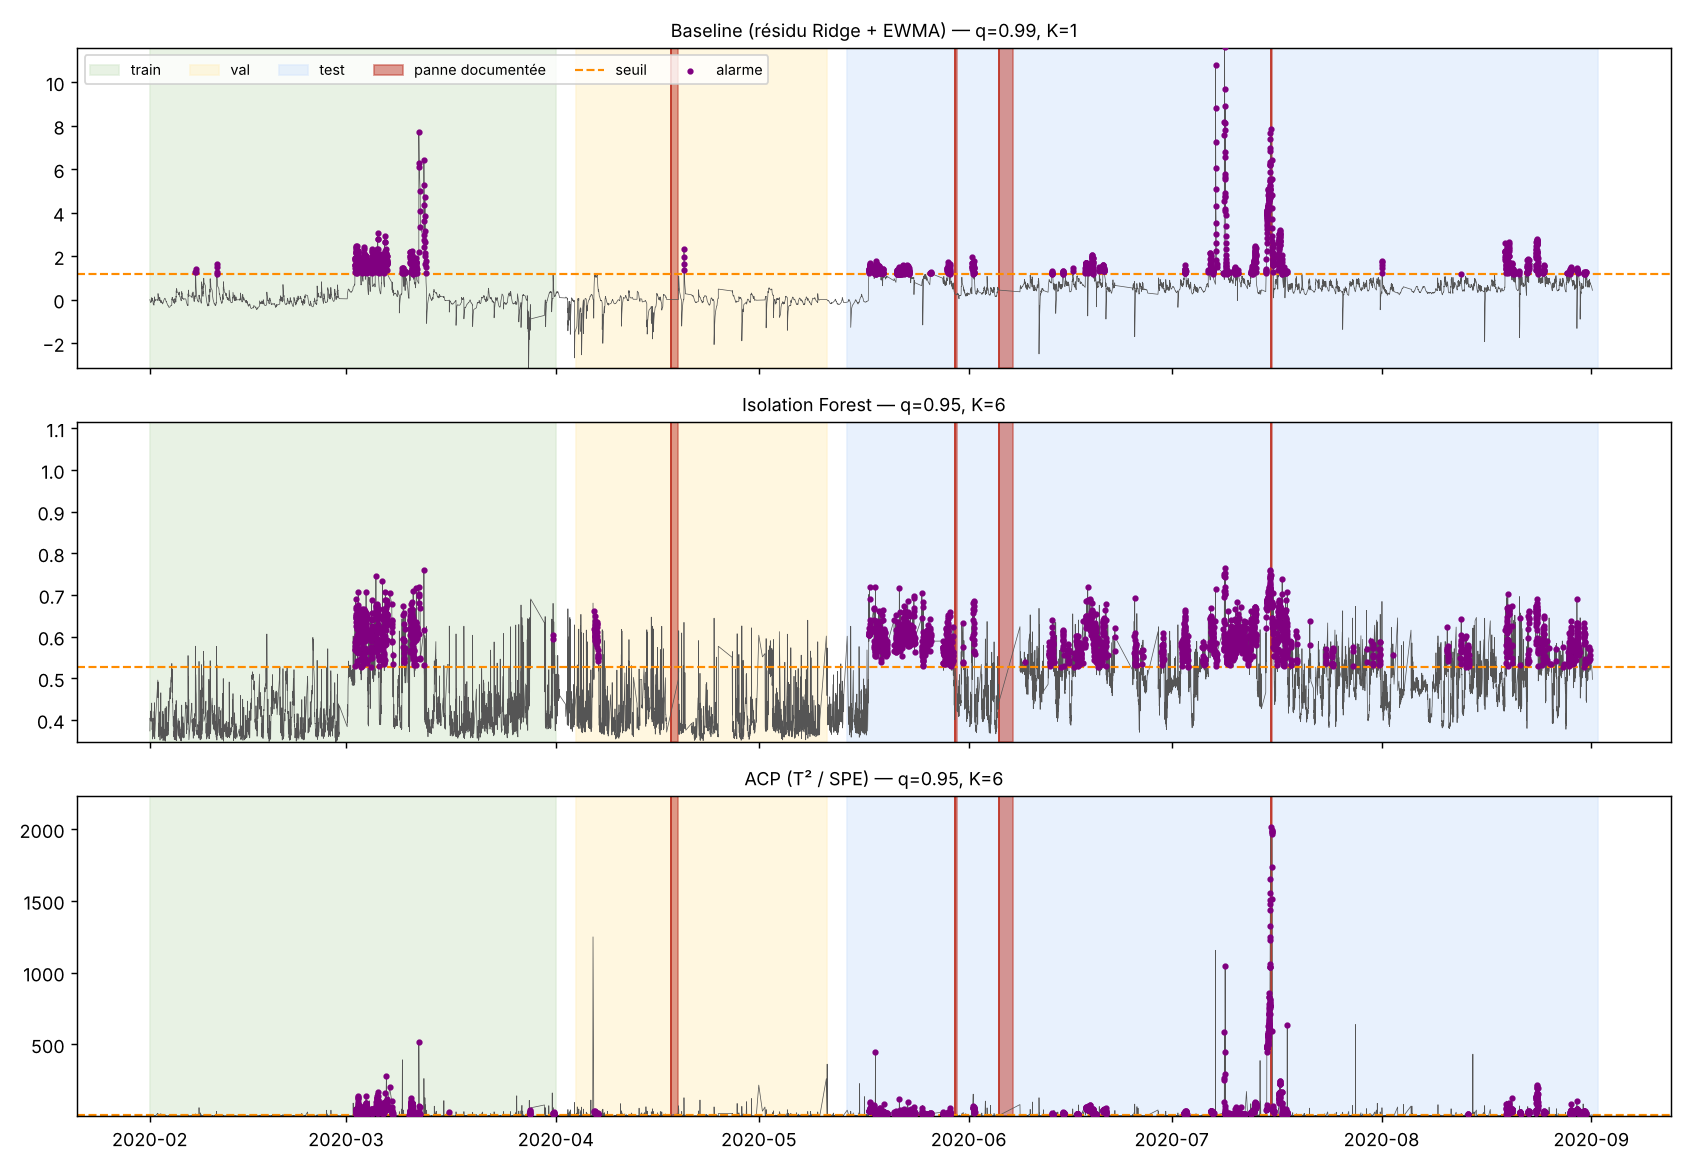

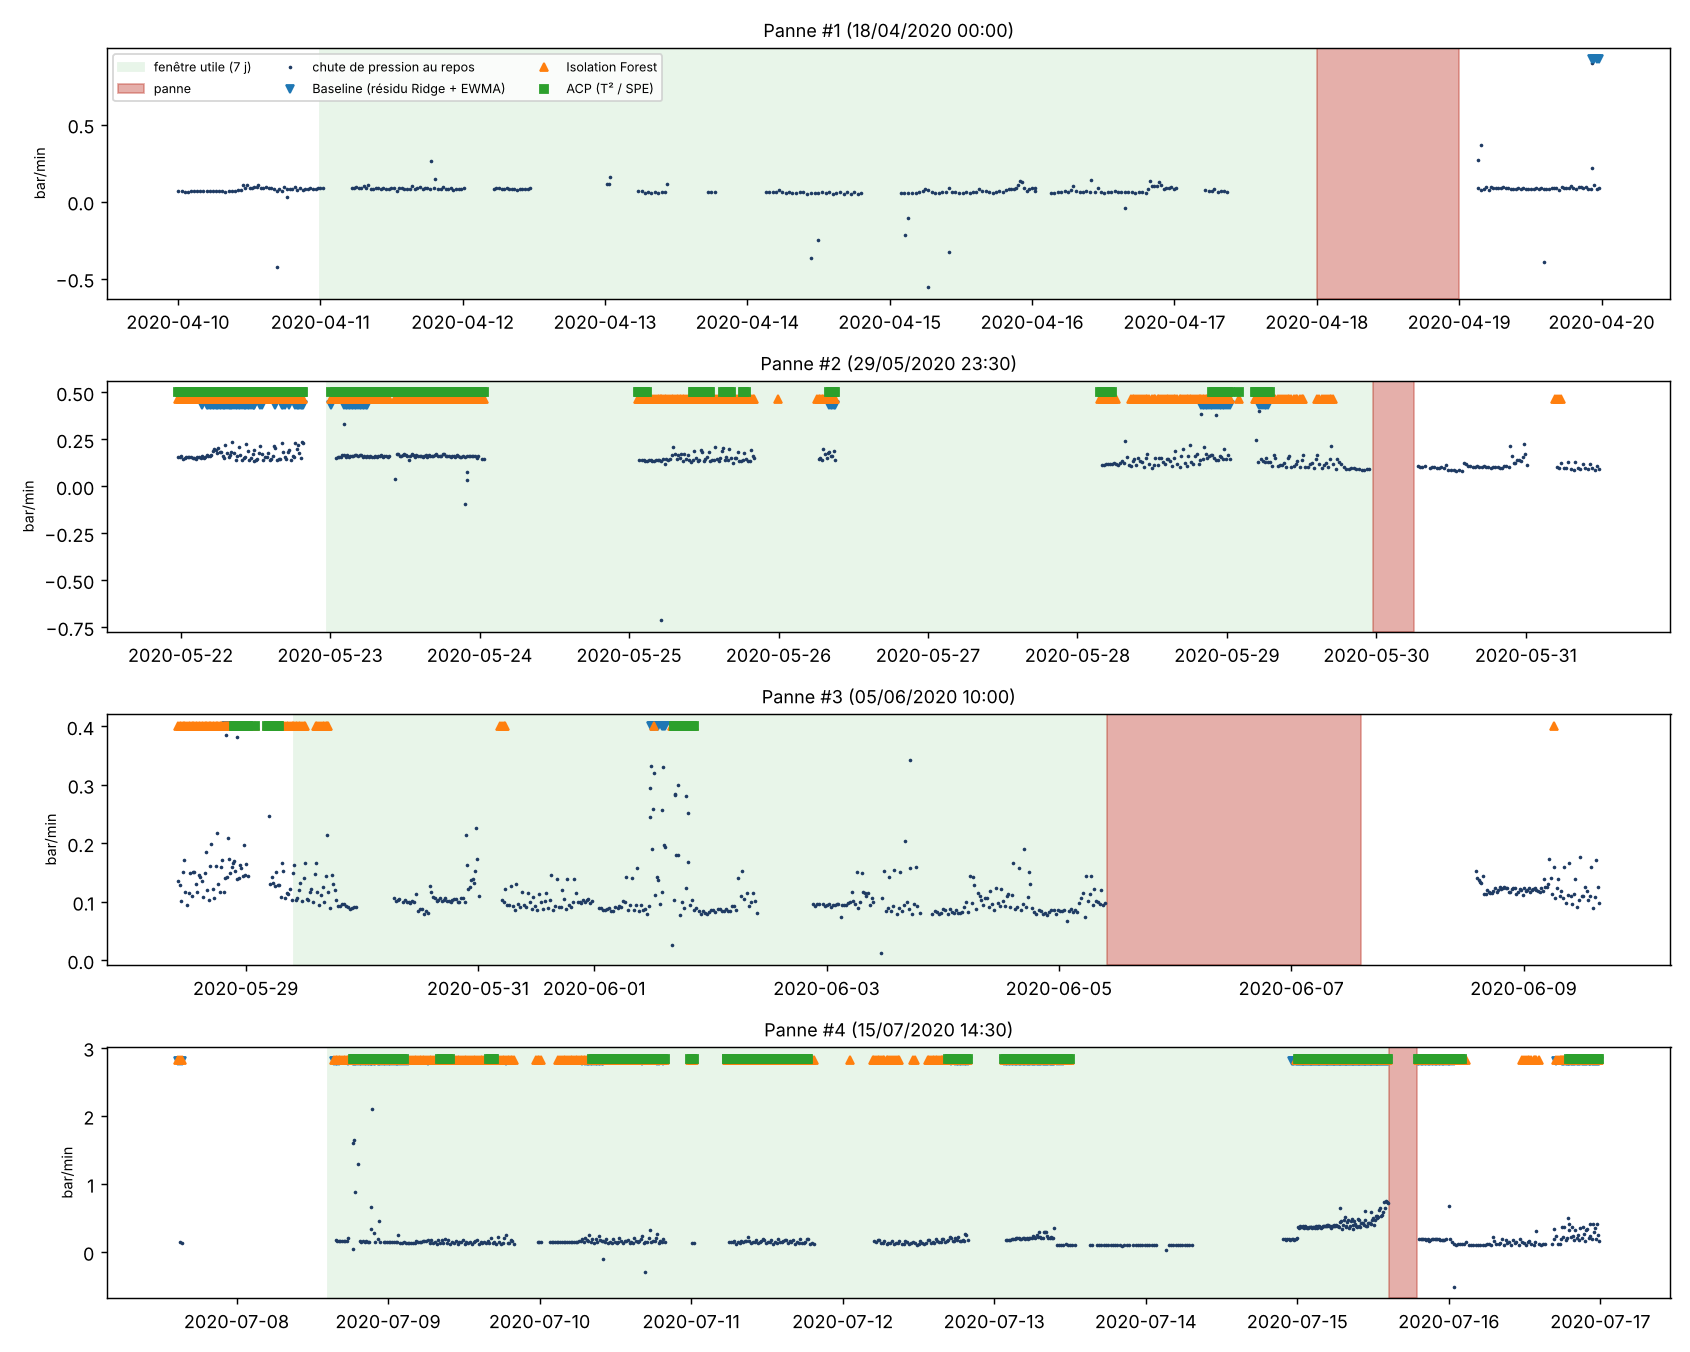

In [11]:
display(Image(FIG / "03_frise_detections.png")); display(Image(FIG / "04_zoom_pannes.png"))

**Lecture.**
* Sur le test, les trois détecteurs alertent **avant** les pannes #2, #3 et #4 (3/3, IC 95 % Clopper-Pearson [0,29 ; 1]). L'avance affichée (~164–168 h) est **plafonnée par la fenêtre de 7 j** : l'alarme était déjà active au début de la fenêtre (dérive lente : P très en amont de F).
* La panne #1 (validation) n'est détectée par aucun modèle : les capteurs sont figés dès le 17/04 10 h et il n'y a pas de dérive visible avant.
* Le prix à payer : **5 à 7 épisodes de fausse alerte par mois** sur le test, parce que la consommation d'air reste durablement plus élevée qu'en février à partir de mi-mai (dérive / saison). Avec ce taux d'épisodes, un détecteur **aléatoire** aurait déjà ~71–81 % de chances de tomber dans une fenêtre de 7 j : à 7 jours, le gain sur le hasard est faible ; il est net à 1–3 jours (tableau de sensibilité ci-dessous).

In [12]:
pd.read_csv(RES / "sensibilite_fenetre.csv").pivot_table(index="detecteur", columns="fenetre_j", values=["detectees", "rappel_aleatoire"])

detectees                     rappel_aleatoire                            
fenetre_j                             1    3    5    7    14               1      3      5      7      14
detecteur                                                                                                
ACP (T² / SPE)                       2.0  2.0  3.0  3.0  3.0            0.181  0.448  0.610  0.735  0.930
Baseline (résidu Ridge + EWMA)       2.0  2.0  3.0  3.0  3.0            0.181  0.429  0.586  0.711  0.911
Isolation Forest                     2.0  2.0  3.0  3.0  3.0            0.215  0.516  0.692  0.814  0.973

---
## Ablation (Isolation Forest) : retirer un groupe de capteurs à la fois
Chaque variante est ré-entraînée sur le train et re-réglée sur la validation (même protocole).

In [13]:
pd.read_csv(RES / "ablation.csv")

,variante,n_variables,q,K,val_detectees,val_FA_mois,test_detectees,test_FA_mois,test_avances_h
0,complet,12,0.950,6,0,1.13,3,7.32,"[167.3, 167.7, 167.0]"
1,sans duree,10,0.980,3,0,1.13,3,6.55,"[167.3, 130.1, 166.3]"
2,sans repos_fuite,9,0.980,6,0,1.13,3,5.39,"[167.3, 89.6, 164.0]"
3,sans thermique,11,0.995,1,1,1.13,3,8.48,"[167.3, 89.4, 164.0]"
4,sans electrique,10,0.980,3,0,1.13,3,6.17,"[167.3, 129.8, 165.8]"
5,sans tendances,8,0.950,6,0,0.00,2,1.93,"[None, 93.7, 163.6]"
6,seulement repos_fuite,3,0.950,3,0,1.13,3,5.01,"[165.3, 130.1, 166.3]"


* Les indicateurs **repos / fuite** (chute de pression au repos, rapport de service) portent l'essentiel du signal : à eux seuls ils détectent 3/3 avec moins de fausses alertes que le modèle complet.
* Retirer les **tendances glissantes** divise les fausses alertes par ~4 mais fait manquer la panne #2 : les tendances capturent la dérive lente.
* Les groupes thermique et électrique apportent peu (et la température d'huile suit la saison).

---
## Coût d'une fausse alerte face à une panne en service (question 5)
Hypothèses (ordre de grandeur, à valider avec l'exploitant) : fausse alerte = inspection au dépôt ≈ 150 € ; vraie alerte = réparation planifiée ≈ 200 € ; panne en ligne = immobilisation, remorquage, pénalités ≈ 20 000 €.

In [14]:
c = pd.read_csv(RES / "couts_test.csv"); c

,strategie,FA,pannes_ratees,cout_total_EUR
0,Aucune surveillance (maintenance corrective),0,3,60000.0
1,Baseline (résidu Ridge + EWMA),14,0,2700.0
2,Isolation Forest,19,0,3450.0
3,ACP (T² / SPE),15,0,2850.0


Avec un rapport de coûts ≈ 130, une détection anticipée « rembourse » environ 130 fausses alertes : même à 5–7 FA/mois, la surveillance divise le coût par ~15 sur la période de test.
La contrainte réelle n'est donc pas financière mais **opérationnelle** (confiance des équipes, « fatigue d'alarme ») : il faut réduire les fausses alertes liées à la dérive (référence adaptative, recalibrage après maintenance — voir *Limites* dans le rapport).